In [13]:
import os
import joblib
import numpy as np
import pandas as pd

print("Libraries imported successfully.")

Libraries imported successfully.


In [14]:
MODEL_PATH = "../models/improved_random_forest_glucose_model.pkl"
FEATURE_PATH = "../models/feature_columns.pkl"

model = joblib.load(MODEL_PATH)
feature_columns = joblib.load(FEATURE_PATH)

print("Model loaded successfully.")
print("Expected features:", len(feature_columns))
print(feature_columns)

Model loaded successfully.
Expected features: 18
['glucose_value', 'glucose_lag_1', 'glucose_lag_2', 'glucose_lag_3', 'glucose_lag_6', 'glucose_change_5min', 'glucose_change_15min', 'meal_carbs', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_duration', 'exercise_intensity', 'sleep_duration_hours', 'sleep_quality', 'finger_stick_value', 'hour', 'day_of_week']


In [15]:
DATA_PATH = "../data/processed/ml_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded.")
print("Shape:", df.shape)

Dataset loaded.
Shape: (65499, 21)


In [16]:
# Select a patient state with meaningful lifestyle activity

candidates = df[
    (
        (df["meal_carbs"] >= 30) |
        (df["exercise_duration"] > 0) |
        (df["sleep_duration_hours"] > 0)
    )
].copy()

# Select a sample with the highest lifestyle activity
sample = candidates.sort_values(
    by=[
        "meal_carbs",
        "exercise_duration",
        "sleep_duration_hours"
    ],
    ascending=False
).iloc[0].copy()

print("Selected patient:", sample["Patient"])
print("Timestamp:", sample["timestamp"])
print()
print("Current glucose:", sample["glucose_value"])
print("Meal carbs:", sample["meal_carbs"])
print("Exercise duration:", sample["exercise_duration"])
print("Exercise intensity:", sample["exercise_intensity"])
print("Sleep duration:", sample["sleep_duration_hours"])
print("Sleep quality:", sample["sleep_quality"])
print("Bolus dose:", sample["bolus_dose"])

Selected patient: 544-ws-training
Timestamp: 2027-05-28 17:55:00

Current glucose: 91
Meal carbs: 162.0
Exercise duration: 0.0
Exercise intensity: 0.0
Sleep duration: 8.716666666666667
Sleep quality: 2.0
Bolus dose: 14.1


In [17]:
def predict_glucose(state):
    X = pd.DataFrame([state])[feature_columns]
    prediction = model.predict(X)[0]
    return prediction

baseline_prediction = predict_glucose(sample)

print("Current glucose:", sample["glucose_value"], "mg/dL")
print("Baseline 30-minute prediction:", round(baseline_prediction, 2), "mg/dL")

Current glucose: 91 mg/dL
Baseline 30-minute prediction: 94.7 mg/dL


In [23]:
# Decision threshold
IMPROVEMENT_THRESHOLD = 2.0  # mg/dL

# Get baseline prediction
baseline = scenario_results.loc[
    scenario_results["Scenario"] == "Current Lifestyle",
    "Predicted_Glucose_30min"
].iloc[0]

# Get alternative scenarios
alternative_results = scenario_results[
    scenario_results["Scenario"] != "Current Lifestyle"
].copy()

# Calculate improvement
alternative_results["Improvement"] = (
    baseline - alternative_results["Predicted_Glucose_30min"]
)

# Find scenarios with meaningful improvement
beneficial = alternative_results[
    alternative_results["Improvement"] >= IMPROVEMENT_THRESHOLD
]

if len(beneficial) > 0:

    best_scenario = beneficial.loc[
        beneficial["Improvement"].idxmax()
    ]

    print("Baseline prediction:", round(baseline, 2), "mg/dL")
    print()
    print("Best simulated scenario:")
    print("Scenario:", best_scenario["Scenario"])
    print(
        "Predicted glucose:",
        round(best_scenario["Predicted_Glucose_30min"], 2),
        "mg/dL"
    )
    print(
        "Estimated improvement:",
        round(best_scenario["Improvement"], 2),
        "mg/dL"
    )

else:

    print("Baseline prediction:", round(baseline, 2), "mg/dL")
    print()
    print("No scenario produced a meaningful simulated improvement.")
    print("Decision: Maintain current lifestyle state.")

Baseline prediction: 94.7 mg/dL

No scenario produced a meaningful simulated improvement.
Decision: Maintain current lifestyle state.


In [19]:
results = []

for name, state in scenarios.items():
    prediction = predict_glucose(state)

    results.append({
        "Scenario": name,
        "Predicted_Glucose_30min": prediction
    })

scenario_results = pd.DataFrame(results)

scenario_results["Predicted_Glucose_30min"] = (
    scenario_results["Predicted_Glucose_30min"].round(2)
)

scenario_results

,Scenario,Predicted_Glucose_30min
0,Current Lifestyle,94.70
1,Reduced Carbohydrates,93.94
2,Increased Exercise,94.70
3,Improved Sleep,98.35


In [20]:
baseline = scenario_results.loc[
    scenario_results["Scenario"] == "Current Lifestyle",
    "Predicted_Glucose_30min"
].iloc[0]

scenario_results["Change_from_Baseline"] = (
    scenario_results["Predicted_Glucose_30min"] - baseline
).round(2)

scenario_results

,Scenario,Predicted_Glucose_30min,Change_from_Baseline
0,Current Lifestyle,94.70,0.00
1,Reduced Carbohydrates,93.94,-0.76
2,Increased Exercise,94.70,0.00
3,Improved Sleep,98.35,3.65


In [21]:
alternative_results = scenario_results[
    scenario_results["Scenario"] != "Current Lifestyle"
]

best_scenario = alternative_results.loc[
    alternative_results["Predicted_Glucose_30min"].idxmin()
]

print("Baseline prediction:", baseline, "mg/dL")
print()
print("Best simulated scenario:")
print("Scenario:", best_scenario["Scenario"])
print(
    "Predicted glucose:",
    best_scenario["Predicted_Glucose_30min"],
    "mg/dL"
)
print(
    "Change:",
    best_scenario["Change_from_Baseline"],
    "mg/dL"
)

Baseline prediction: 94.7 mg/dL

Best simulated scenario:
Scenario: Reduced Carbohydrates
Predicted glucose: 93.94 mg/dL
Change: -0.76 mg/dL


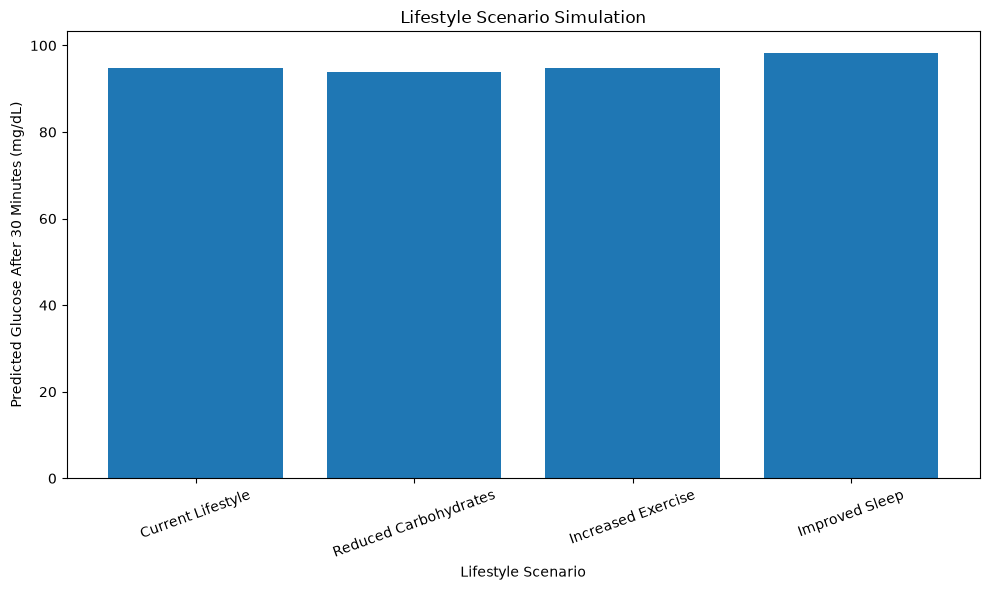

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    scenario_results["Scenario"],
    scenario_results["Predicted_Glucose_30min"]
)

plt.xlabel("Lifestyle Scenario")
plt.ylabel("Predicted Glucose After 30 Minutes (mg/dL)")
plt.title("Lifestyle Scenario Simulation")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()